# Data Splitting + Tokenizer Training & Evaluation 

In [1]:
import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "sentencepiece", "matplotlib"])


0

In [2]:
# Set to "hindi" or "nepali"
LANG = "nepali"

# Path to the cleaned data directory (output of the cleaning notebook)
# Should contain .jsonl files like wikipedia.jsonl, indiccorp.jsonl, etc.
CLEANED_DIR = "/kaggle/input/datasets/srinivasu2005/cleaned-nepali-dataset/cleaned"

# Splitting config
SPLIT_SEED = 42
SPLIT_RATIOS = [0.96, 0.02, 0.02]

# Tokenizer config
# We will search these vocab sizes to find the best balance of fertility and UNK rate
CANDIDATE_VOCAB_SIZES = [8000, 16000, 24000, 32000, 48000] if LANG == "hindi" else [4000, 8000, 16000, 24000]
MODEL_TYPE = "unigram"    # 'unigram' or 'bpe'
CHARACTER_COVERAGE = 0.9995
BYTE_FALLBACK = False
SPLIT_DIGITS = True

# Output paths
OUTPUT_DIR = "/kaggle/working"
SPLITS_DIR = f"{OUTPUT_DIR}/splits"
TOKENIZER_DIR = f"{OUTPUT_DIR}/tokenizer"
REPORT_DIR = f"{OUTPUT_DIR}/report"


In [3]:
import gc, json, logging, os, random
from pathlib import Path
from typing import Dict, List, Tuple
import matplotlib.pyplot as plt

logging.basicConfig(level=logging.INFO, format="[%(asctime)s] %(levelname)s — %(message)s", datefmt="%H:%M:%S")
logger = logging.getLogger("split_tokenizer")
logger.setLevel(logging.INFO)


In [4]:
def count_tokens(text: str) -> int:
    return len(text.split())

def format_number(n: int) -> str:
    if n >= 1_000_000: return f"{n/1_000_000:.2f}M"
    if n >= 1_000: return f"{n/1_000:.1f}K"
    return str(n)


## Part 1: Data Splitting
Loads cleaned JSONL files, shuffles, and creates deterministic train/val/test splits.


In [5]:
def load_cleaned_documents(cleaned_dir: str) -> List[str]:
    """Load all cleaned documents from JSONL files in the cleaned directory."""
    documents = []
    cleaned_path = Path(cleaned_dir)
    if not cleaned_path.exists():
        logger.error(f"Cleaned directory not found: {cleaned_dir}")
        return documents
    for filepath in sorted(cleaned_path.iterdir()):
        if filepath.suffix == ".jsonl":
            with open(filepath, "r", encoding="utf-8") as f:
                for line in f:
                    line = line.strip()
                    if not line: continue
                    try:
                        obj = json.loads(line)
                        text = obj.get("text", "").strip()
                        if text: documents.append(text)
                    except json.JSONDecodeError: continue
        elif filepath.suffix == ".txt":
            with open(filepath, "r", encoding="utf-8") as f:
                content = f.read()
            for para in content.split("\n\n"):
                para = para.strip()
                if para: documents.append(para)
    logger.info(f"Loaded {len(documents):,} cleaned documents from {cleaned_dir}")
    return documents

def split_documents(documents, ratios=None, seed=42):
    """Split documents into train/val/test with fixed seed."""
    if ratios is None: ratios = [0.96, 0.02, 0.02]
    shuffled = list(documents)
    random.seed(seed)
    random.shuffle(shuffled)
    n = len(shuffled)
    train_end = int(n * ratios[0])
    val_end = train_end + int(n * ratios[1])
    return shuffled[:train_end], shuffled[train_end:val_end], shuffled[val_end:]

def save_split(docs, filepath):
    """Save docs to file, one doc per entry, separated by blank lines."""
    os.makedirs(os.path.dirname(filepath), exist_ok=True)
    with open(filepath, "w", encoding="utf-8") as f:
        for i, doc in enumerate(docs):
            f.write(doc)
            if i < len(docs) - 1: f.write("\n\n")
    return len(docs)

def run_splitting():
    """Run the full splitting pipeline."""
    logger.info(f"{'='*60}\nSplitting {LANG} data (seed={SPLIT_SEED}, ratios={SPLIT_RATIOS})\n{'='*60}")
    documents = load_cleaned_documents(CLEANED_DIR)
    if not documents:
        logger.error("No cleaned documents found! Run cleaning first.")
        return {}
    train, val, test = split_documents(documents, SPLIT_RATIOS, SPLIT_SEED)
    save_split(train, f"{SPLITS_DIR}/train.txt")
    save_split(val, f"{SPLITS_DIR}/val.txt")
    save_split(test, f"{SPLITS_DIR}/test.txt")
    train_tok = sum(count_tokens(d) for d in train)
    val_tok = sum(count_tokens(d) for d in val)
    test_tok = sum(count_tokens(d) for d in test)
    stats = {
        "total_docs": len(documents),
        "train_docs": len(train), "val_docs": len(val), "test_docs": len(test),
        "train_tokens": train_tok, "val_tokens": val_tok, "test_tokens": test_tok,
        "seed": SPLIT_SEED, "ratios": SPLIT_RATIOS,
    }
    logger.info(f"Split: {len(train):,} train / {len(val):,} val / {len(test):,} test")
    logger.info(f"Tokens: {train_tok:,} train / {val_tok:,} val / {test_tok:,} test")
    logger.info(f"Saved to {SPLITS_DIR}/")
    return stats


In [6]:
split_stats = run_splitting()


[03:55:51] INFO — ============================================================
Splitting nepali data (seed=42, ratios=[0.96, 0.02, 0.02])
[03:58:01] INFO — Loaded 11,958,680 cleaned documents from /kaggle/input/datasets/srinivasu2005/cleaned-nepali-dataset/cleaned
[04:00:10] INFO — Split: 11,480,332 train / 239,173 val / 239,175 test
[04:00:10] INFO — Tokens: 491,008,773 train / 10,232,865 val / 10,200,024 test
[04:00:10] INFO — Saved to /kaggle/working/splits/


## Part 2: Tokenizer Training
Trains a SentencePiece Unigram (or BPE) tokenizer from scratch on train.txt.


In [7]:
def train_single_tokenizer(vocab_size, train_file):
    import sentencepiece as spm
    os.makedirs(TOKENIZER_DIR, exist_ok=True)
    model_prefix = f"{TOKENIZER_DIR}/tokenizer_{vocab_size}"
    
    logger.info(f"  Training SentencePiece model with vocab size: {vocab_size}...")
    spm.SentencePieceTrainer.train(
        input=train_file,
        model_prefix=model_prefix,
        model_type=MODEL_TYPE,
        vocab_size=vocab_size,
        character_coverage=CHARACTER_COVERAGE,
        byte_fallback=BYTE_FALLBACK,
        split_digits=SPLIT_DIGITS,
        num_threads=os.cpu_count(),
        pad_id=0, unk_id=1, bos_id=2, eos_id=3,
        pad_piece="<|pad|>", unk_piece="<|unk|>", bos_piece="<|bos|>", eos_piece="<|eos|>",
        input_sentence_size=1_000_000,
        train_extremely_large_corpus=True,
        shuffle_input_sentence=True,
        normalization_rule_name="nfkc",
        remove_extra_whitespaces=True,
        add_dummy_prefix=True,
    )
    
    sp = spm.SentencePieceProcessor()
    sp.load(f"{model_prefix}.model")
    return sp, model_prefix


# --- Evaluation Functions (Moved up for NameError fix) ---
def load_eval_text(max_lines=5000):
    """Load validation text for evaluation."""
    val_file = f"{SPLITS_DIR}/val.txt"
    if not os.path.exists(val_file):
        logger.error(f"Validation file not found: {val_file}")
        return []
    lines = []
    with open(val_file, "r", encoding="utf-8") as f:
        for i, line in enumerate(f):
            if i >= max_lines: break
            text = line.strip()
            if text: lines.append(text)
    logger.info(f"Loaded {len(lines)} eval lines from val.txt")
    return lines

def compute_fertility(sp, texts):
    total_tokens, total_words = 0, 0
    for text in texts:
        total_words += len(text.split())
        total_tokens += len(sp.encode(text, out_type=int))
    return total_tokens / total_words if total_words else 0.0

def compute_avg_chars_per_token(sp, texts):
    total_chars, total_tokens = 0, 0
    for text in texts:
        for piece in sp.encode(text, out_type=str):
            clean = piece.replace("▁", "")
            if clean.startswith("<0x") and clean.endswith(">"): total_chars += 1
            else: total_chars += len(clean)
            total_tokens += 1
    return total_chars / total_tokens if total_tokens else 0.0

def compute_unk_rate(sp, texts):
    unk_id = sp.unk_id()
    total, unks = 0, 0
    for text in texts:
        for tid in sp.encode(text, out_type=int):
            total += 1
            if tid == unk_id: unks += 1
    return unks / total if total else 0.0

def get_tokenization_examples(sp, texts, n=5):
    sorted_texts = sorted(texts[:100], key=len)
    step = max(1, len(sorted_texts) // n)
    selected = sorted_texts[::step][:n]
    examples = []
    for text in selected:
        if len(text) > 200: text = text[:200] + "..."
        ids = sp.encode(text, out_type=int)
        pieces = sp.encode(text, out_type=str)
        decoded = sp.decode(ids)
        examples.append({
            "input": text, "tokens": pieces[:30], "num_tokens": len(ids),
            "token_ids": ids[:30], "decoded": decoded[:200],
        })
    return examples

def compute_token_frequencies(sp, texts, top_k=15):
    from collections import Counter
    counts = Counter()
    total_tokens = 0
    for text in texts:
        tokens = sp.encode(text, out_type=str)
        counts.update(tokens)
        total_tokens += len(tokens)
    
    top_tokens = [{"token": k, "count": v, "percentage": round((v/total_tokens)*100, 4) if total_tokens else 0} 
                  for k, v in counts.most_common(top_k)]
    unique_used = len(counts)
    vocab_size = sp.get_piece_size()
    coverage = unique_used / vocab_size if vocab_size else 0
    
    return {
        "top_tokens": top_tokens,
        "unique_tokens_used_in_eval": unique_used,
        "vocab_coverage_percent": round(coverage * 100, 2),
        "total_eval_tokens": total_tokens
    }


def search_vocab_sizes():
    train_file = f"{SPLITS_DIR}/train.txt"
    if not os.path.exists(train_file):
        logger.error(f"Training file not found: {train_file}. Run splitting first.")
        return None

    logger.info(f"{'='*60}\nSearching Optimal Vocab Size for {LANG}\n{'='*60}")
    logger.info(f"Candidates: {CANDIDATE_VOCAB_SIZES}")
    
    # We need the evaluation text to test fertility and UNK rate during the search
    eval_texts = load_eval_text()
    if not eval_texts: return None
    
    results = []
    
    for size in CANDIDATE_VOCAB_SIZES:
        sp, prefix = train_single_tokenizer(size, train_file)
        fertility = compute_fertility(sp, eval_texts)
        unk_rate = compute_unk_rate(sp, eval_texts)
        results.append({
            "size": size,
            "fertility": fertility,
            "unk_rate": unk_rate,
            "sp": sp,
            "prefix": prefix
        })
        logger.info(f"    -> Size {size}: Fertility = {fertility:.3f}, UNK Rate = {unk_rate:.6f}")
        
    # Plotting
    os.makedirs(REPORT_DIR, exist_ok=True)
    sizes = [r["size"] for r in results]
    fertilities = [r["fertility"] for r in results]
    unk_rates = [r["unk_rate"] * 100 for r in results] # as percentage
    
    fig, ax1 = plt.subplots(figsize=(10, 5))
    color = 'tab:blue'
    ax1.set_xlabel('Vocabulary Size')
    ax1.set_ylabel('Fertility (tokens/word)', color=color)
    ax1.plot(sizes, fertilities, marker='o', color=color, linewidth=2, label="Fertility")
    ax1.tick_params(axis='y', labelcolor=color)
    ax1.axhline(y=1.5, color='gray', linestyle='--', alpha=0.5, label="Max Target Fertility")
    
    ax2 = ax1.twinx()
    color = 'tab:red'
    ax2.set_ylabel('UNK Rate (%)', color=color)
    ax2.plot(sizes, unk_rates, marker='s', color=color, linewidth=2, label="UNK Rate")
    ax2.tick_params(axis='y', labelcolor=color)
    
    plt.title(f"Vocabulary Size Search for {LANG.capitalize()}")
    fig.tight_layout()
    
    plot_path = f"{REPORT_DIR}/vocab_search_{LANG}.png"
    plt.savefig(plot_path, dpi=300)
    logger.info(f"Saved vocabulary search graph to {plot_path}")
    
    # Select the best size (minimize UNK rate while keeping fertility below 1.5, or just pick the lowest unk rate)
    # We prefer the smallest vocab that gets UNK rate < 0.1% (0.001)
    best_result = None
    for r in results:
        if r["unk_rate"] < 0.001:
            best_result = r
            break
    if not best_result:
        # Fallback to the one with the absolute lowest UNK rate
        best_result = min(results, key=lambda x: x["unk_rate"])
        
    logger.info(f"\n*** Selected Optimal Vocab Size: {best_result['size']} ***")
    
    # Save the selected model as the main tokenizer
    final_prefix = f"{TOKENIZER_DIR}/tokenizer"
    import shutil
    shutil.copy(f"{best_result['prefix']}.model", f"{final_prefix}.model")
    shutil.copy(f"{best_result['prefix']}.vocab", f"{final_prefix}.vocab")
    
    logger.info(f"Saved optimal model to {final_prefix}.model")
    return best_result["sp"]


[04:00:15] INFO — ============================================================
Searching Optimal Vocab Size for nepali
[04:00:15] INFO — Candidates: [4000, 8000, 16000, 24000]
[04:00:15] INFO — Loaded 2506 eval lines from val.txt
[04:00:15] INFO —   Training SentencePiece model with vocab size: 4000...
sentencepiece_trainer.cc(78) LOG(INFO) Starts training with : 
trainer_spec {
  input: /kaggle/working/splits/train.txt
  input_format: 
  model_prefix: /kaggle/working/tokenizer/tokenizer_4000
  model_type: UNIGRAM
  vocab_size: 4000
  self_test_sample_size: 0
  character_coverage: 0.9995
  input_sentence_size: 1000000
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 4
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 1
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces:

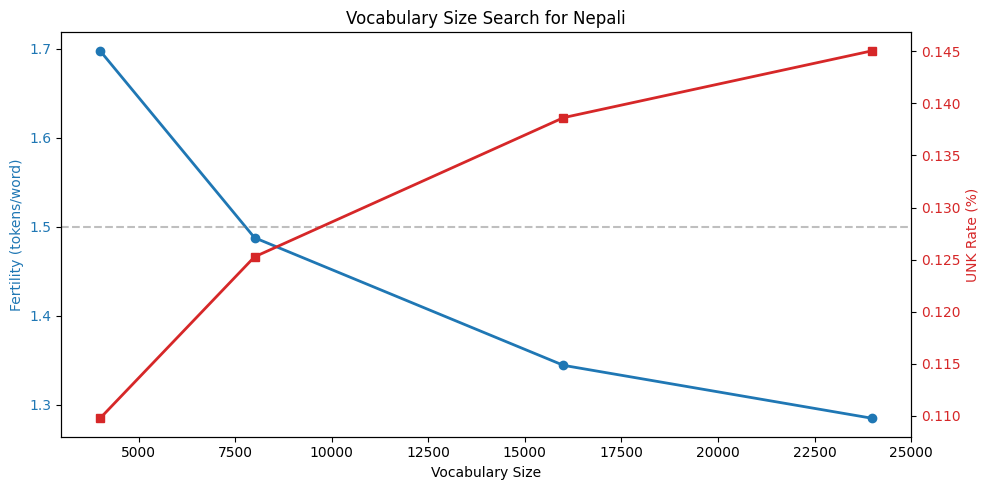

In [8]:
sp = search_vocab_sizes()


## Part 3: Tokenizer Evaluation
Computes fertility, avg chars/token, UNK rate on the validation split.


In [9]:
def evaluate_tokenizer(sp):
    """Run full evaluation and save results."""
    logger.info(f"\n{'='*60}\nEvaluating {LANG} tokenizer\n{'='*60}")
    texts = load_eval_text()
    if not texts:
        logger.error("No eval text loaded!"); return {}

    fertility = compute_fertility(sp, texts)
    avg_chars = compute_avg_chars_per_token(sp, texts)
    unk_rate = compute_unk_rate(sp, texts)
    examples = get_tokenization_examples(sp, texts)
    freq_stats = compute_token_frequencies(sp, texts)

    results = {
        "language": LANG,
        "tokenizer_type": f"SentencePiece {MODEL_TYPE.upper()}",
        "vocab_size": sp.get_piece_size(),
        "fertility": round(fertility, 4),
        "avg_chars_per_token": round(avg_chars, 4),
        "unk_rate": round(unk_rate, 6),
        "eval_lines": len(texts),
        "token_frequencies": freq_stats,
        "examples": examples,
    }

    logger.info(f"\nResults for {LANG}:")
    logger.info(f"  Tokenizer type:     {results['tokenizer_type']}")
    logger.info(f"  Vocab size:         {results['vocab_size']}")
    logger.info(f"  Fertility:          {results['fertility']:.4f} tokens/word")
    logger.info(f"  Avg chars/token:    {results['avg_chars_per_token']:.4f}")
    logger.info(f"  UNK rate:           {results['unk_rate']:.6f} ({results['unk_rate']*100:.4f}%)")
    logger.info(f"  Vocab coverage:     {freq_stats['vocab_coverage_percent']}%")
    logger.info(f"  Top 5 tokens:       {[t['token'] for t in freq_stats['top_tokens'][:5]]}")

    logger.info(f"\nTokenization examples:")
    for i, ex in enumerate(examples):
        logger.info(f"  Example {i+1}:")
        logger.info(f"    Input:  {ex['input'][:80]}...")
        logger.info(f"    Tokens: {ex['tokens'][:10]}...")
        logger.info(f"    Count:  {ex['num_tokens']} tokens")

    # Save results
    os.makedirs(REPORT_DIR, exist_ok=True)
    eval_path = f"{REPORT_DIR}/tokenizer_eval_{LANG}.json"
    with open(eval_path, "w", encoding="utf-8") as f:
        json.dump({LANG: results}, f, ensure_ascii=False, indent=2)
    logger.info(f"\nResults saved to {eval_path}")

    return results


In [10]:
if sp is not None:
    eval_results = evaluate_tokenizer(sp)


[04:35:56] INFO — 
Evaluating nepali tokenizer
[04:35:56] INFO — Loaded 2506 eval lines from val.txt
[04:35:58] INFO — 
Results for nepali:
[04:35:58] INFO —   Tokenizer type:     SentencePiece UNIGRAM
[04:35:58] INFO —   Vocab size:         4000
[04:35:58] INFO —   Fertility:          1.6976 tokens/word
[04:35:58] INFO —   Avg chars/token:    3.2270
[04:35:58] INFO —   UNK rate:           0.001098 (0.1098%)
[04:35:58] INFO —   Vocab coverage:     101.15%
[04:35:58] INFO —   Top 5 tokens:       ['को', 'मा', '▁।', ',', 'ले']
[04:35:58] INFO — 
Tokenization examples:
[04:35:58] INFO —   Example 1:
[04:35:58] INFO —     Input:  नाम...
[04:35:58] INFO —     Tokens: ['▁नाम']...
[04:35:58] INFO —     Count:  1 tokens
[04:35:58] INFO —   Example 2:
[04:35:58] INFO —     Input:  ‘सेवा र कामका बारेमा बुझाउन केही कठिन भएको थियो। तर बिस्तारै मानिसले बुझ्न थाले ...
[04:35:58] INFO —     Tokens: ['▁‘', 'सेवा', '▁र', '▁काम', 'का', '▁बारेमा', '▁बुझाउन', '▁केही', '▁कठिन', '▁भएको']...
[04:35:58] INFO —

## Summary
All outputs are saved to `/kaggle/working/`:
- `splits/train.txt`, `splits/val.txt`, `splits/test.txt`
- `tokenizer/tokenizer.model`, `tokenizer/tokenizer.vocab`
- `report/tokenizer_eval_{LANG}.json`

**Next step**: Download these outputs and run the report generation notebook,
or proceed to Phase 2 (model training).


In [11]:
all_stats = {"split_stats": split_stats}
if sp is not None and 'eval_results' in dir():
    all_stats["tokenizer_eval"] = eval_results
with open(f"{OUTPUT_DIR}/pipeline_stats_{LANG}.json", "w") as f:
    json.dump(all_stats, f, indent=2, default=str)
logger.info(f"All stats saved to {OUTPUT_DIR}/pipeline_stats_{LANG}.json")


[04:35:58] INFO — All stats saved to /kaggle/working/pipeline_stats_nepali.json
